# 03 — Native-Grid MPAS-Seaice Initial Condition Comparisons (`mosaic`)

This notebook uses [`mosaic`](https://docs.e3sm.org/mosaic/) (`mosaic.Descriptor` + `mosaic.polypcolor`) to render **MPAS-Seaice** initial conditions directly on the unstructured `IcoswISC30E3r5` polygons (`nCells = 235,160`) in North and South Polar Stereographic projections.

All helper functions live in [`util/ic_eval.py`](util/ic_eval.py), and figures are saved to `/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/`.

### Contents
1. **Build `mosaic.Descriptor` objects** for NH and SH polar projections
2. **State & difference maps (`Actual 2015`, `clim`, `obs`, `clim - 2015`, `obs - 2015`)** for NH/SH ice concentration, ice thickness, and snow on ice
3. **Standardized anomaly ($z$) maps** on the native MPAS mesh
4. **4-season NH & SH sea-ice concentration comparison** across all four 2015 dates

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("util").resolve()))
import ic_eval as ice
from clim_restart import source_file

ice.ensure_proj_data()
plt.rcParams["figure.dpi"] = 120

SRC_ROOT     = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
ERA5_ROOT    = Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")
OUT_ROOT     = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
CACHE_DIR    = OUT_ROOT / "cache"
DIAG_ROOT    = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic")
SAVE_DIAG    = True

TEST_DATES   = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]
EXAMPLE_DATE = "2015-02-01"
BOX          = (30.0, 60.0)

plans, distances, selections = ice.load_test_selections(
    TEST_DATES, SRC_ROOT, OUT_ROOT, obs_root=OBS_ROOT, obs_fields=OBS_FIELDS, box=BOX, cache_dir=CACHE_DIR
)

sample_ice_path = source_file(SRC_ROOT, "20251024_s2d_spinup", "mpassi", 2015, EXAMPLE_DATE[5:])
mpassi_desc = ice.build_mpassi_descriptors(sample_ice_path)
print("Loaded MPAS-Seaice mesh:", sample_ice_path.name)

Loaded MPAS-Seaice mesh: 20251024_s2d_spinup.mpassi.rst.2015-02-01_00000.nc


## 1. Native-Mesh State and Difference Maps (`EXAMPLE_DATE`)

Comparing `Actual 2015`, `clim`, `obs`, `clim - 2015`, and `obs - 2015` for all six MPAS-Seaice key fields.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_state_diff_nh_ice_concentration_20150201.png


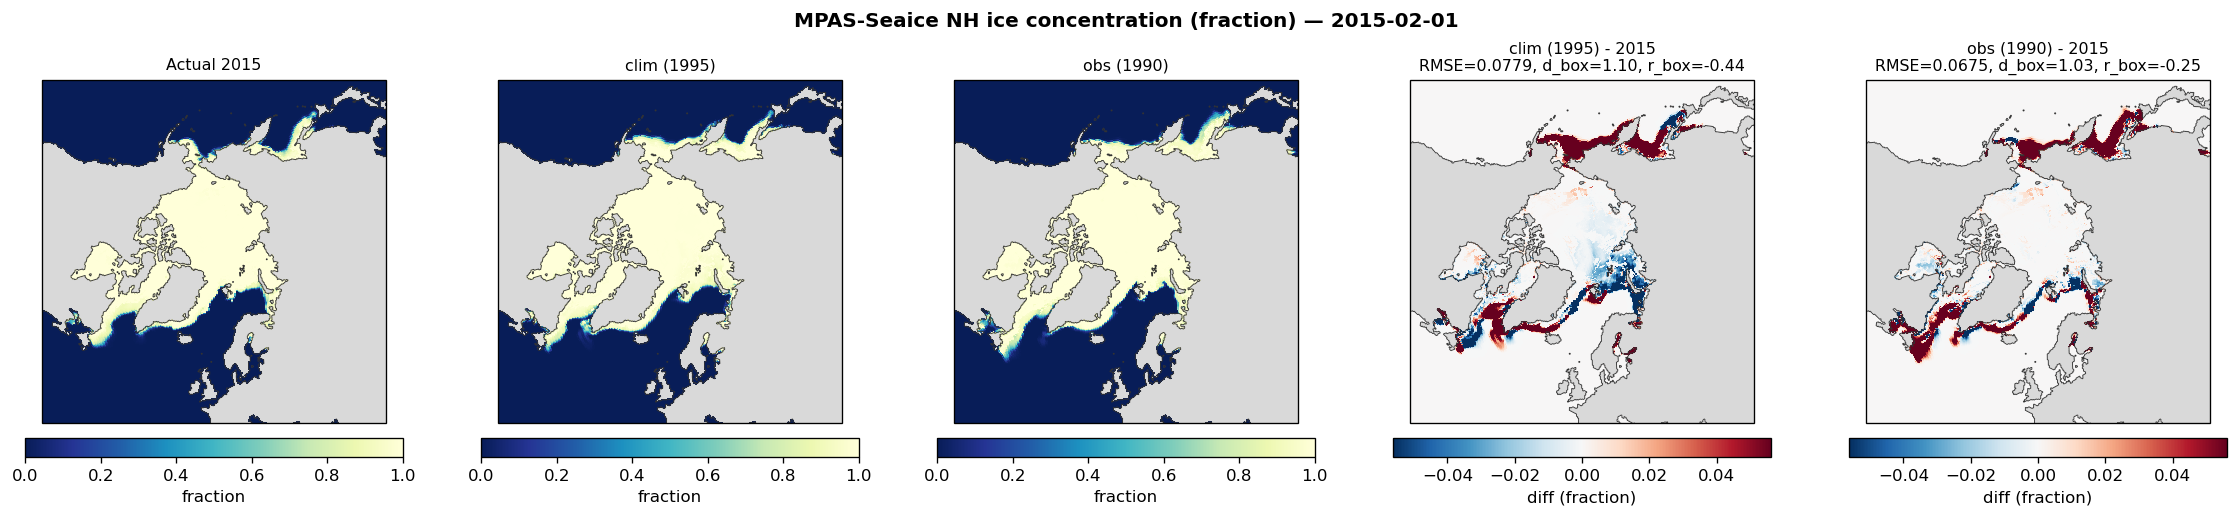

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_state_diff_sh_ice_concentration_20150201.png


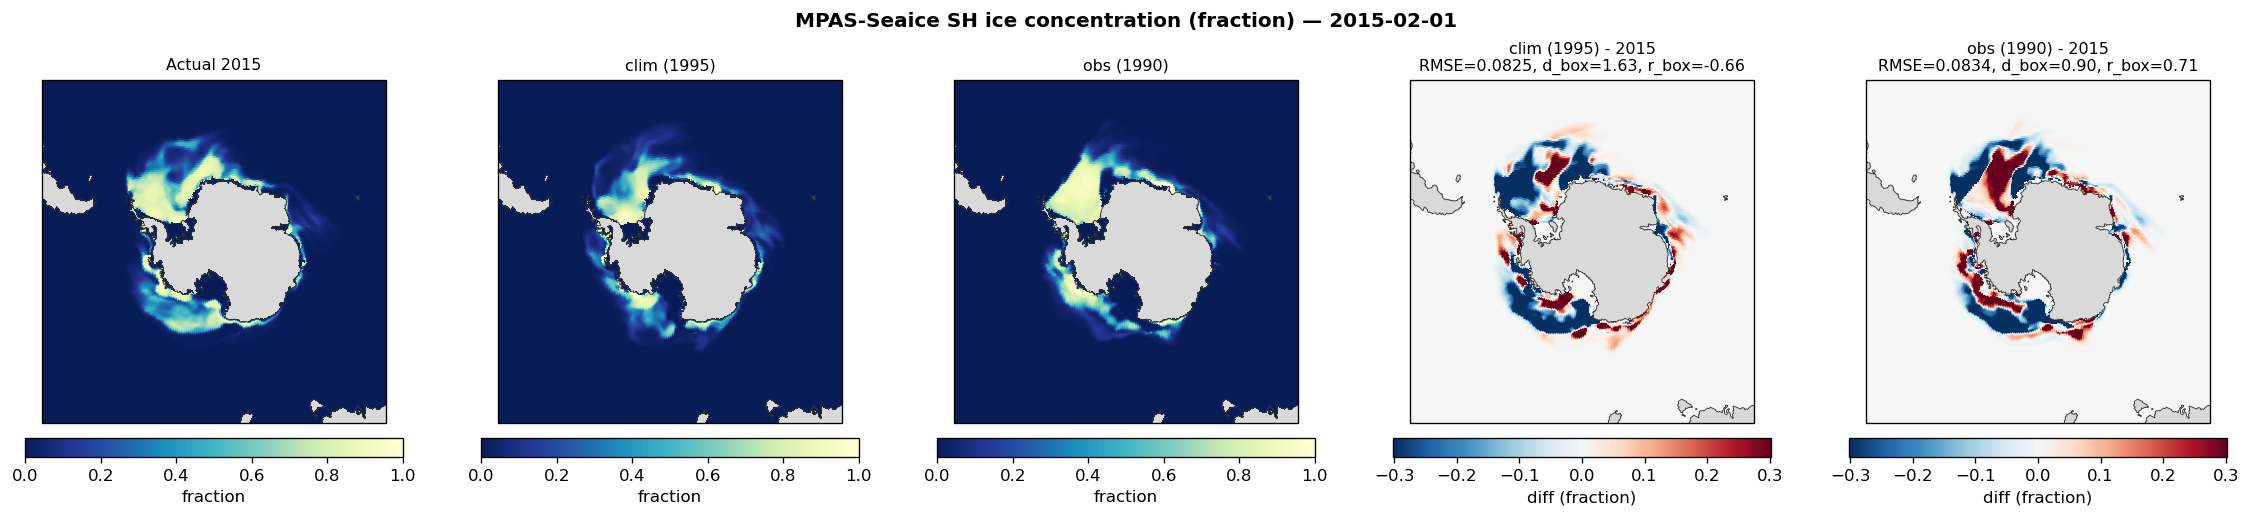

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_state_diff_nh_ice_thickness_20150201.png


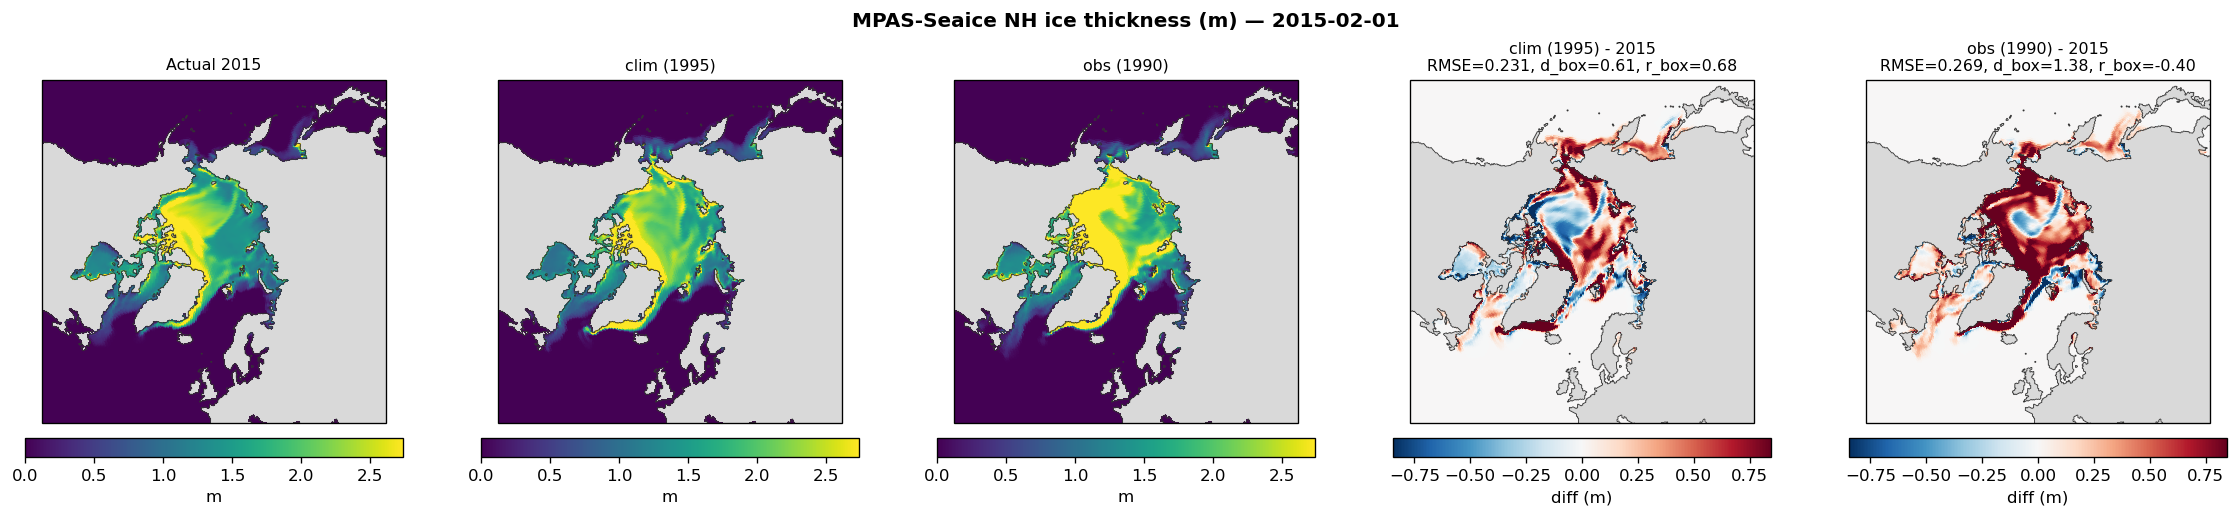

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_state_diff_sh_ice_thickness_20150201.png


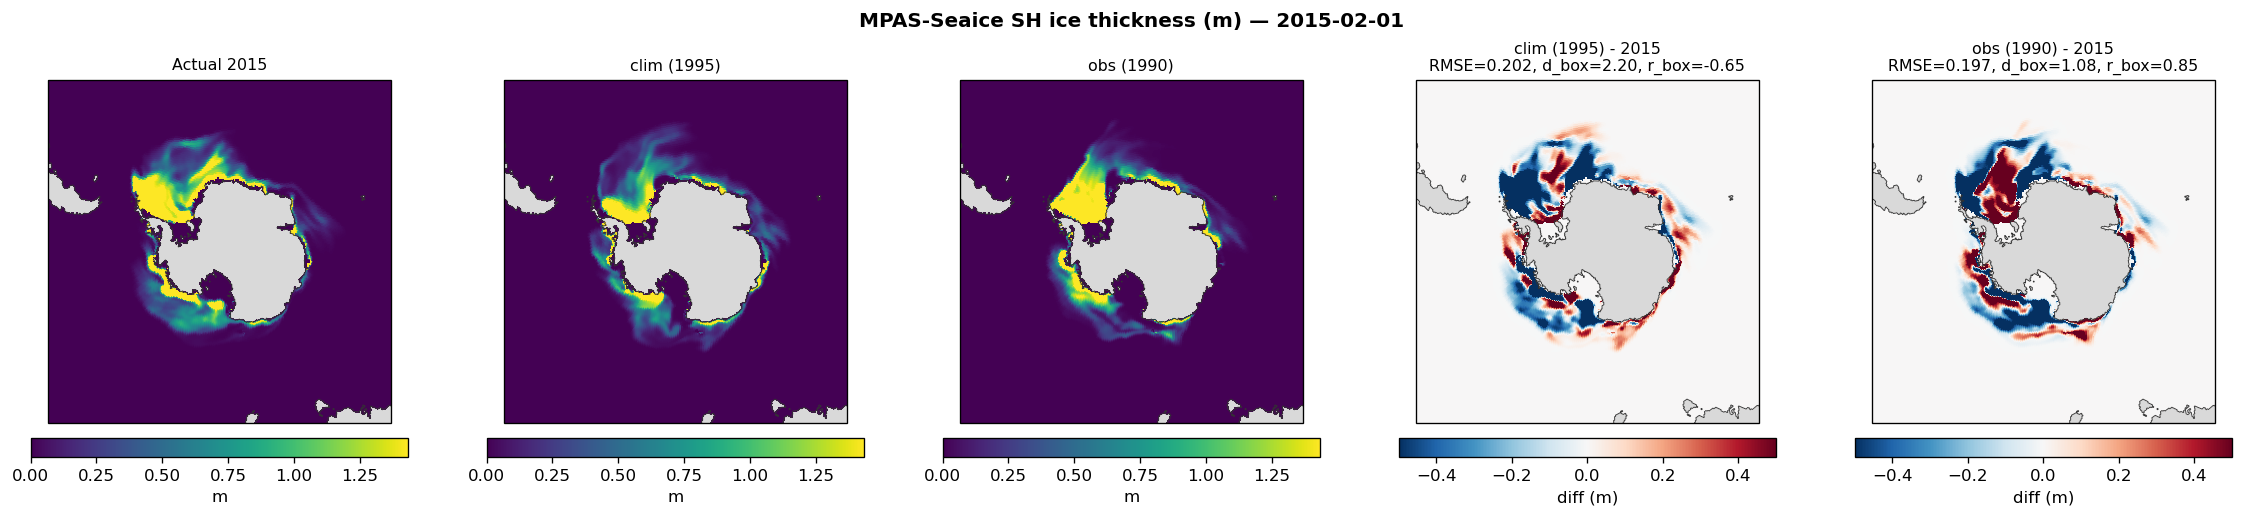

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_state_diff_nh_snow_on_ice_20150201.png


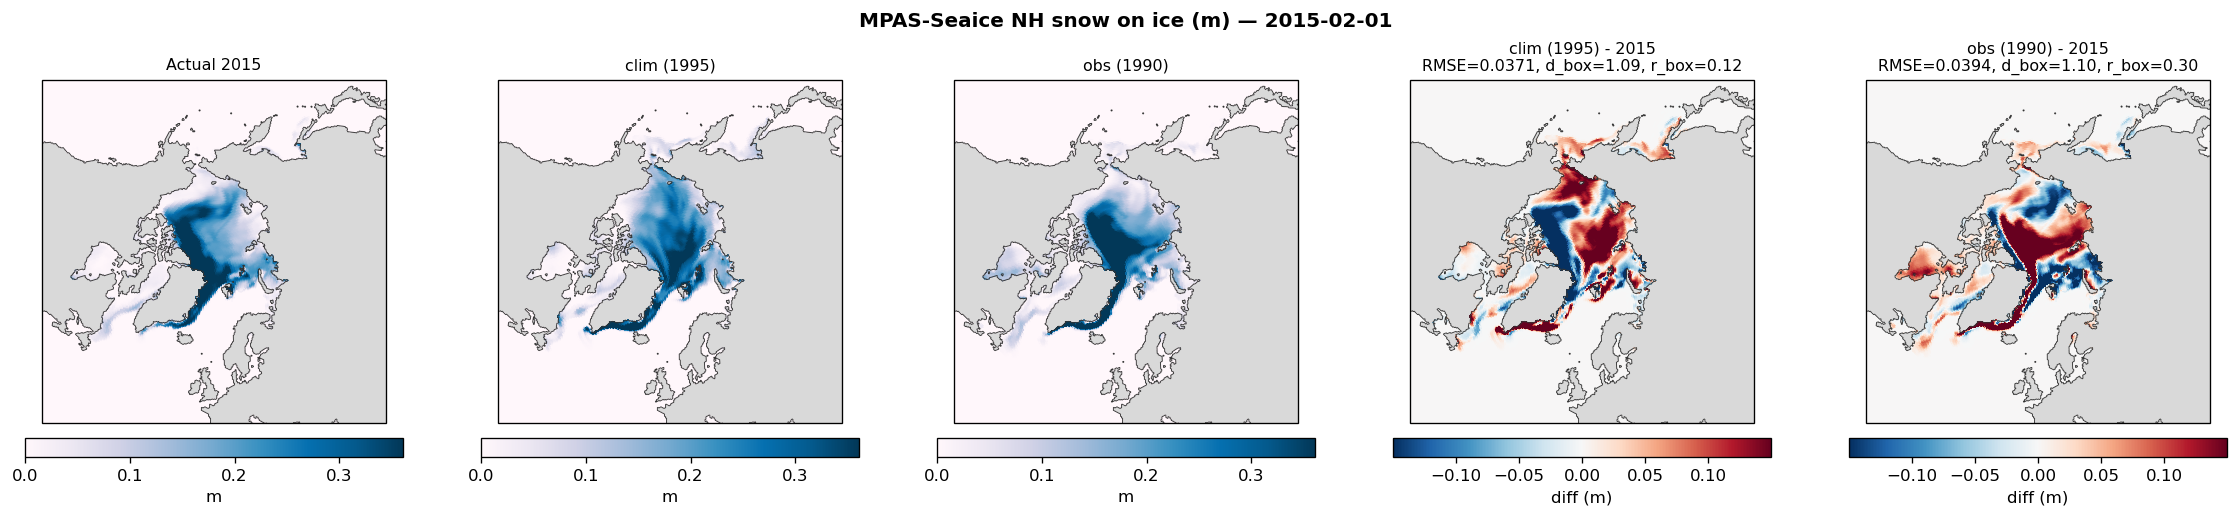

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_state_diff_sh_snow_on_ice_20150201.png


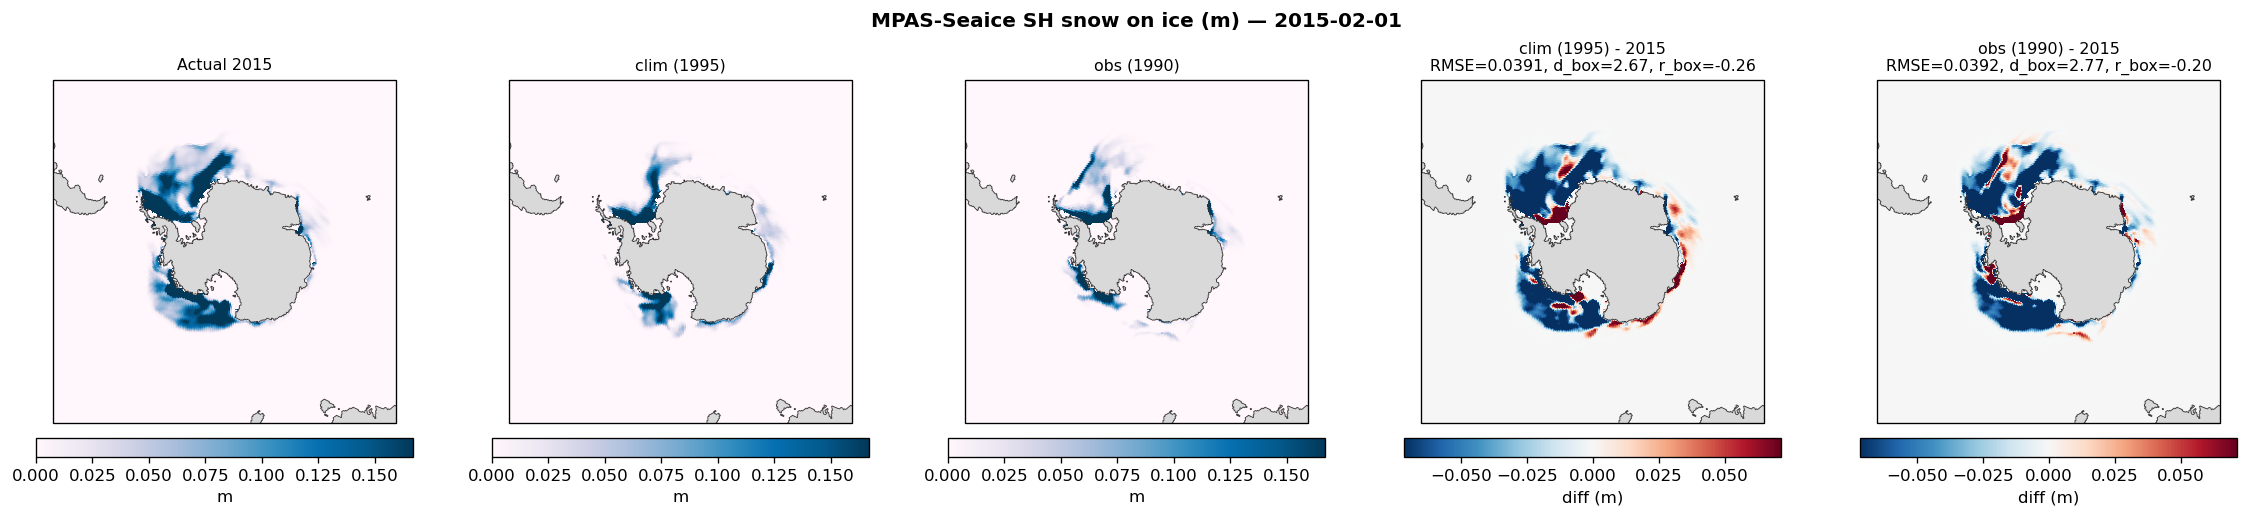

In [2]:
plan_ex = plans["clim", EXAMPLE_DATE]
byears_ex = {
    "clim": selections["clim", EXAMPLE_DATE]["mpassi"],
    "obs": selections["obs", EXAMPLE_DATE]["mpassi"],
}

mpassi_fields = [
    ("NH ice concentration", "YlGnBu_r"),
    ("SH ice concentration", "YlGnBu_r"),
    ("NH ice thickness",     "viridis"),
    ("SH ice thickness",     "viridis"),
    ("NH snow on ice",       "PuBu"),
    ("SH snow on ice",       "PuBu"),
]

spatial_mpassi = {}
for fname, cmap in mpassi_fields:
    sp = ice.prepare_spatial_field(
        plan_ex, "mpassi", fname, 2015, byears_ex, box=BOX, cache_dir=CACHE_DIR, log=lambda *_: None
    )
    spatial_mpassi[fname] = sp
    fig = ice.plot_mpassi_spatial(sp, mpassi_desc, kind="state_and_diff", cmap=cmap)
    ice.save_fig(
        fig, f"mpassi_state_diff_{ice.slugify(fname)}_{EXAMPLE_DATE.replace('-', '')}",
        DIAG_ROOT, SAVE_DIAG,
    )
    plt.show()

## 2. Standardized Anomaly ($z$) Maps on the Native MPAS Mesh

Comparing `Actual 2015 (z)`, `ERA5 2015 (z)`, `obs (z)`, and `clim (z)` on the native unstructured mesh.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_z_nh_ice_concentration_20150201.png


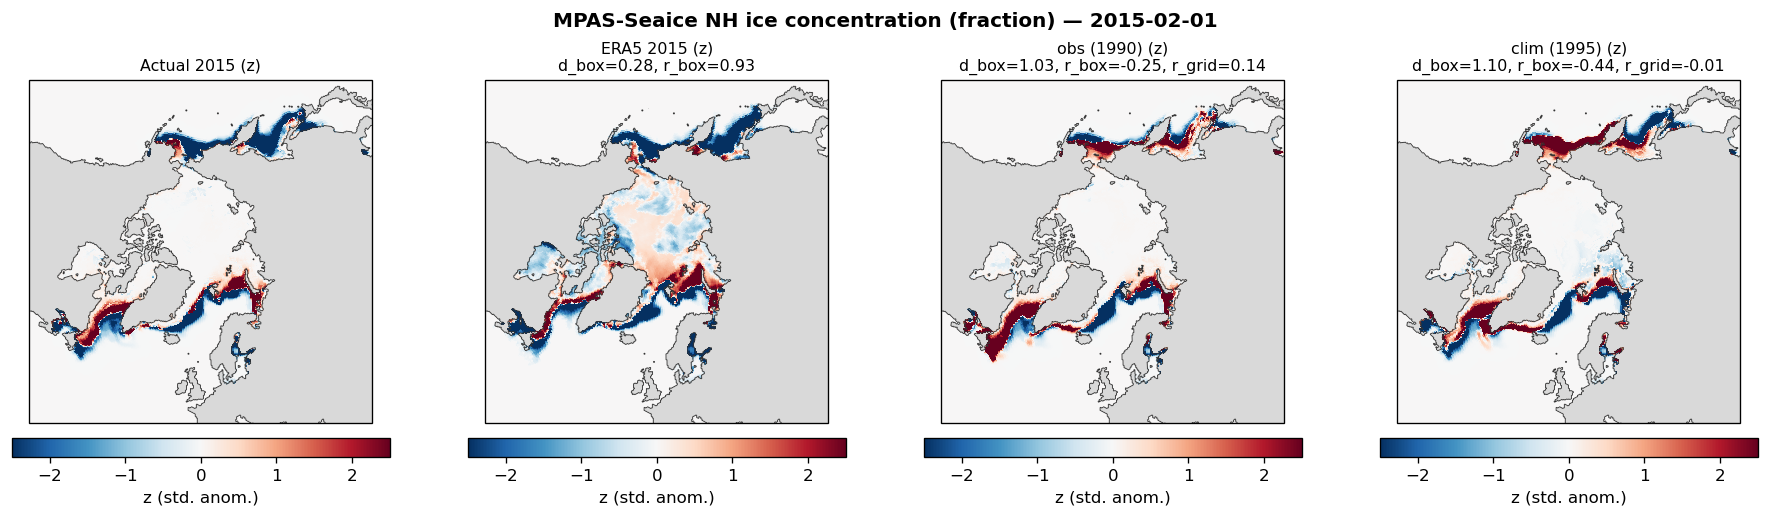

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_z_sh_ice_concentration_20150201.png


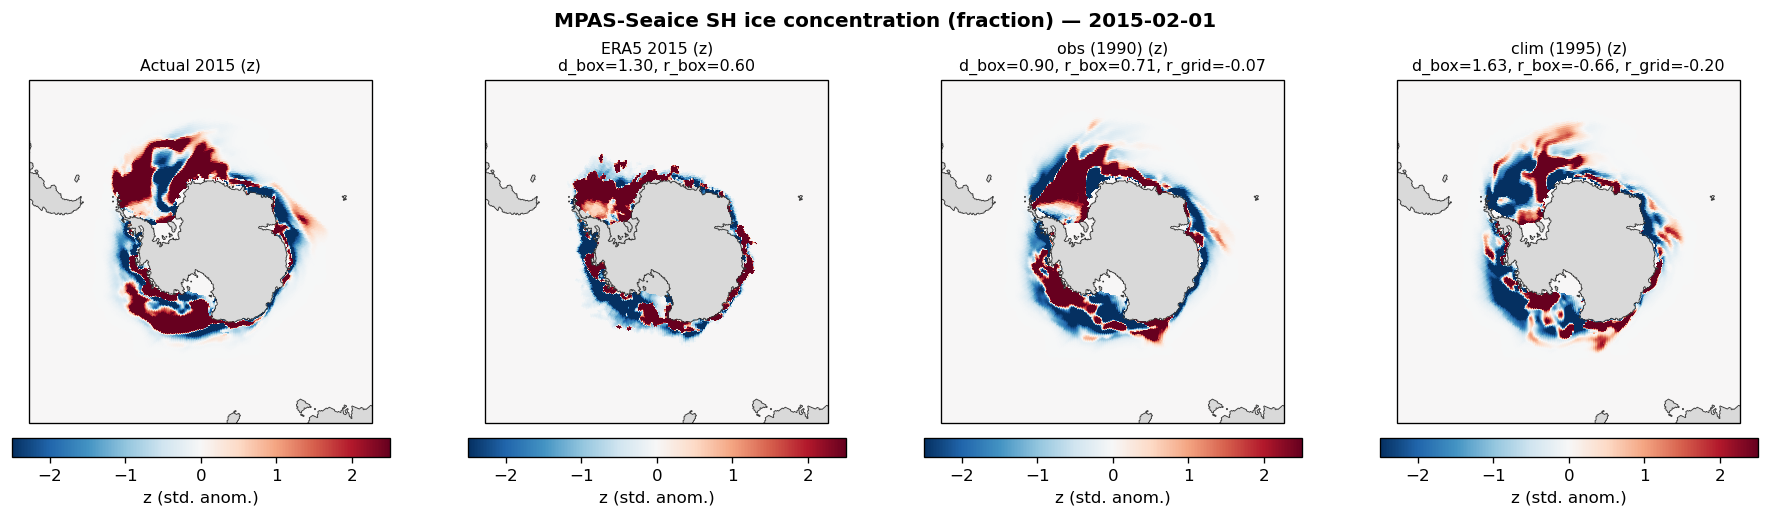

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_z_nh_ice_thickness_20150201.png


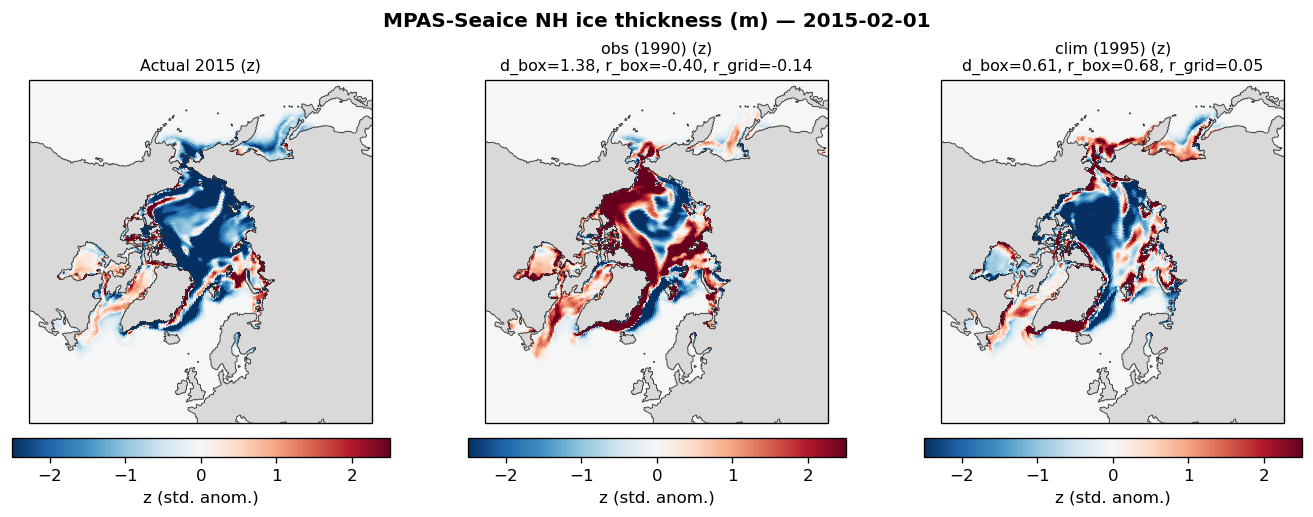

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_z_sh_ice_thickness_20150201.png


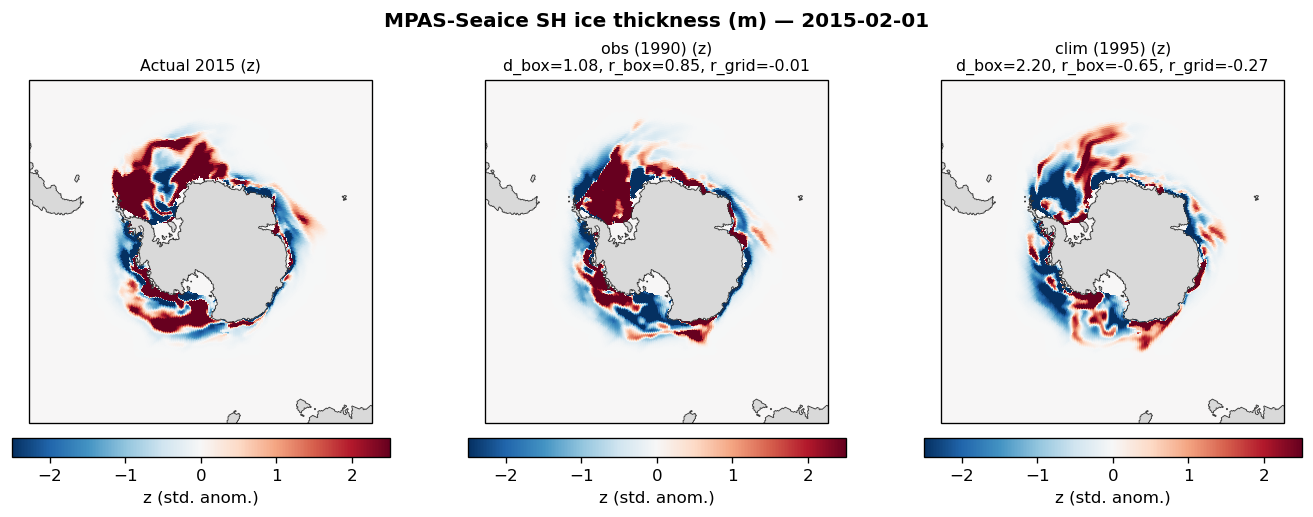

In [3]:
for fname in ["NH ice concentration", "SH ice concentration", "NH ice thickness", "SH ice thickness"]:
    fig = ice.plot_mpassi_spatial(spatial_mpassi[fname], mpassi_desc, kind="z", z_lim=2.5)
    ice.save_fig(
        fig, f"mpassi_z_{ice.slugify(fname)}_{EXAMPLE_DATE.replace('-', '')}",
        DIAG_ROOT, SAVE_DIAG,
    )
    plt.show()

## 3. Four-Season MPAS-Seaice Comparison (`2015-02-01` to `2015-11-01`)

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_4seasons_nh_ice_concentration_2015.png


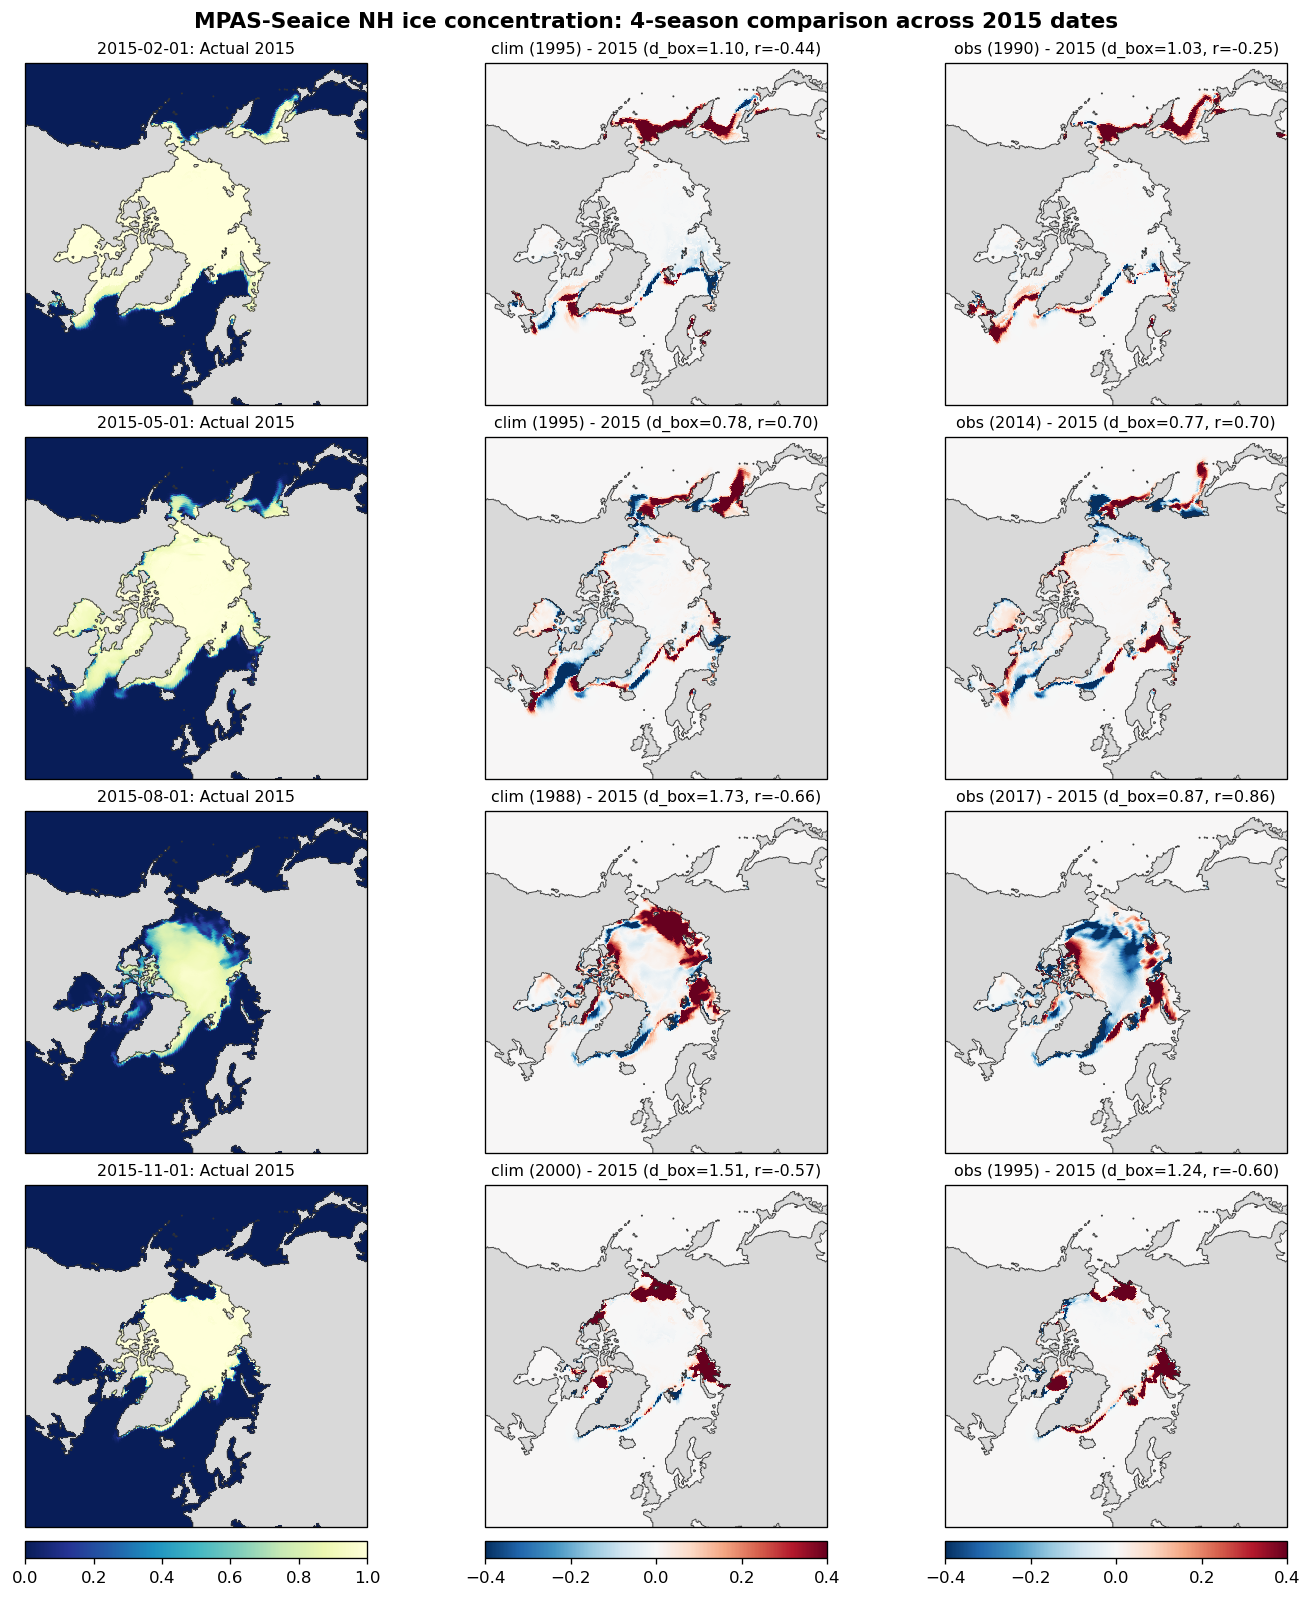

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/figure/mpassi_4seasons_sh_ice_concentration_2015.png


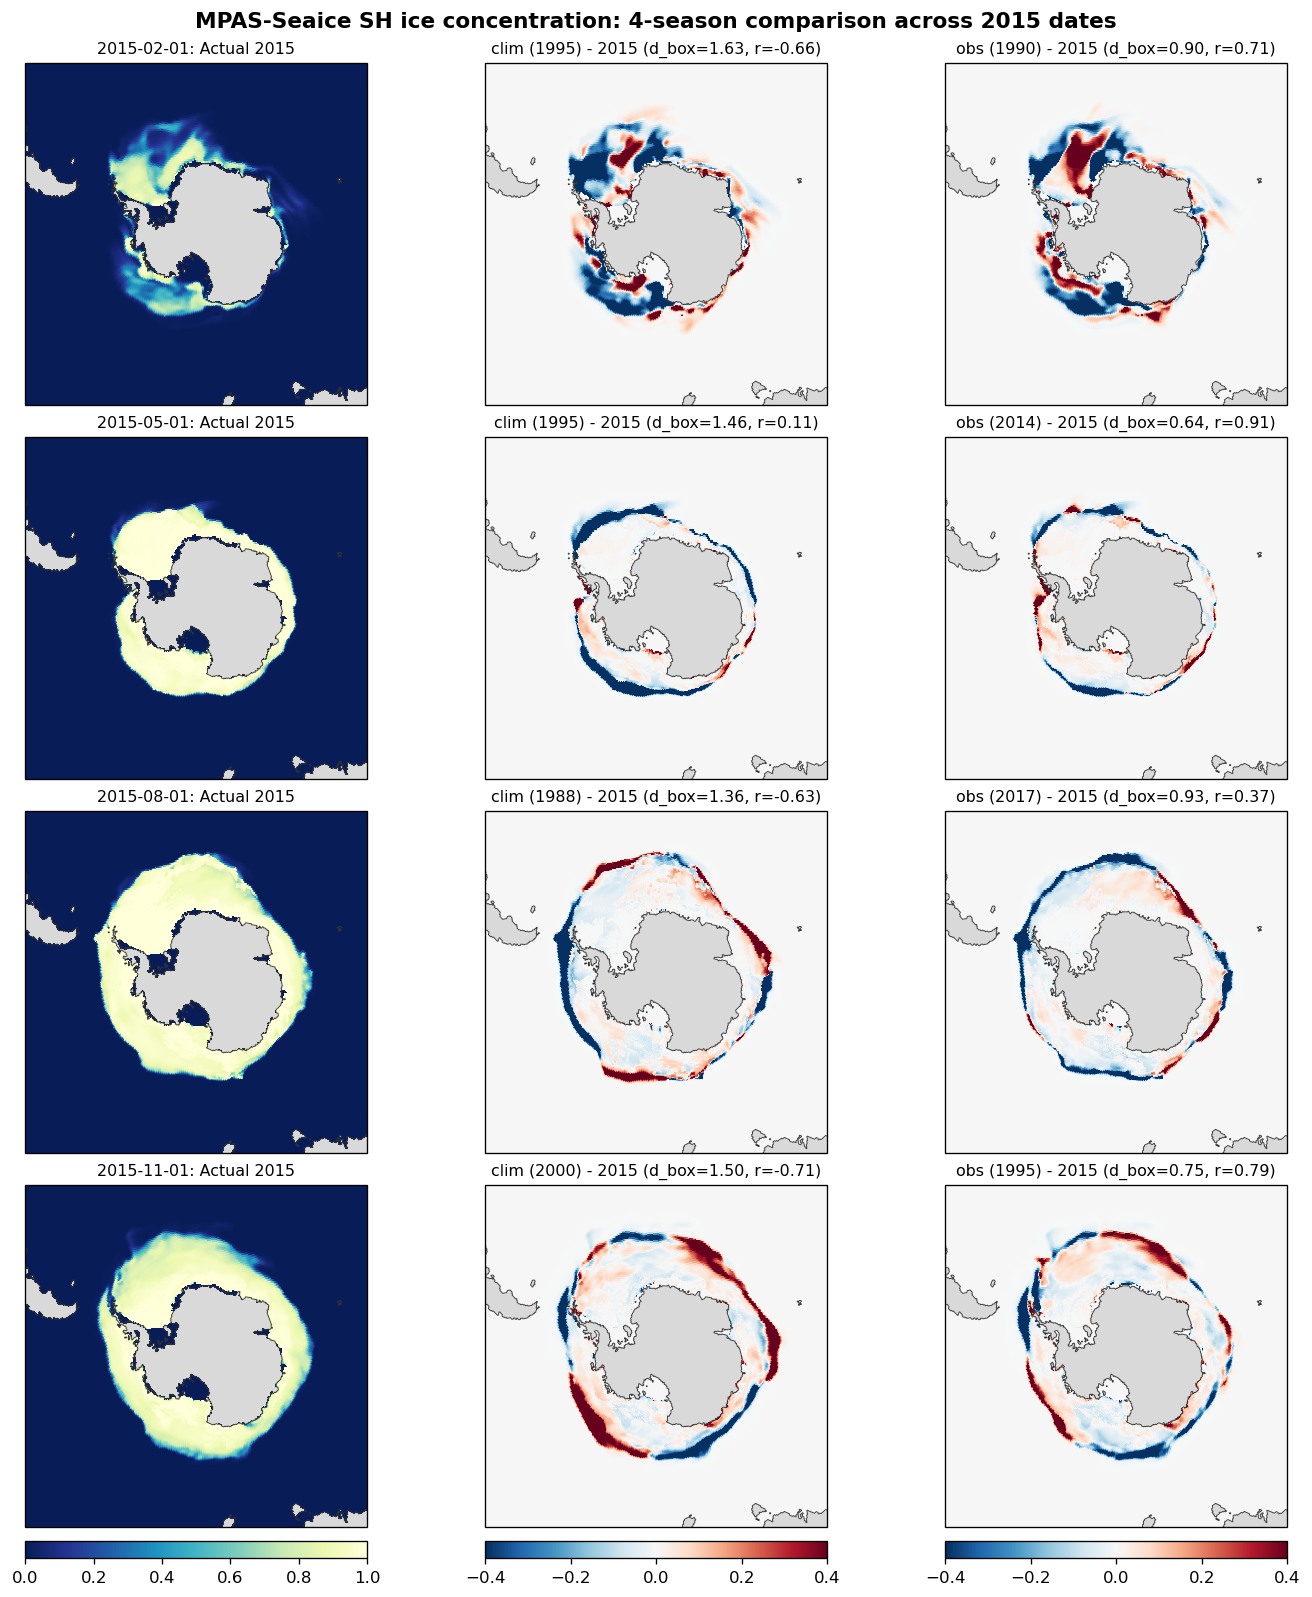

In [4]:
for hemi_field in ["NH ice concentration", "SH ice concentration"]:
    fig = ice.plot_mpassi_four_seasons(
        hemi_field, TEST_DATES, plans, selections, mpassi_desc,
        box=BOX, cache_dir=CACHE_DIR,
    )
    ice.save_fig(fig, f"mpassi_4seasons_{ice.slugify(hemi_field)}_2015", DIAG_ROOT, SAVE_DIAG)
    plt.show()